# Jacobik test suite & debugging hub

A single notebook to run a curated set of chemically-meaningful test complexes,
check the results against independent chemical-realism criteria (not just the
optimized score), and visualize everything needed to debug a regression:
score breakdown by term, IK convergence trace, D&ndash;M&ndash;D angle
distribution, 3D structure, ensemble diversity, and stats-fallback depth.

**How to use this notebook**

- Run top to bottom once to get a pass/fail dashboard across all registered
  cases (`SUMMARY_DF` near the bottom of the batch-run section).
- For anything that fails or looks off, jump to **Debugging playground**
  at the end, set `CASE_NAME` to the case in question, and rerun with
  `debug=True` for full solver diagnostics plus every plot in one place.
- Add new cases by appending to `TEST_CASES` &mdash; nothing else needs to
  change; the batch runner and all checks are generic over the registry.

**Note on `data/notebooks/benchmark_workbench.ipynb`**: that notebook
references `jacobik.vis.benchmark_workbench` and a `benchmarks/` directory
(cases.json, run_case.py) that are **not present in this repository** and
are not recoverable from git history on `main` or `origin/dev` &mdash;
apparently uncommitted work from an earlier session that's now gone. The
`data/out/*_control.json` / `*_baseline.json` files are leftover output
from that lost system. This notebook is a fresh, self-contained
replacement built only against the current, working public API.


## 0. Setup

In [15]:
from __future__ import annotations

import math
import sys,os
import time
from pathlib import Path

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def _find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "jacobik").exists():
            return candidate
    raise RuntimeError(
        "Could not find the Jacobik project root (looked for pyproject.toml "
        "+ src/jacobik above the notebook's directory). Open this notebook "
        "from inside the project tree."
    )

PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from jacobik import ComplexBuilder, LigandInput
from jacobik.stats.stats import StatsLookup, load_db
from jacobik.topology.coord_geom import classify as classify_geometry
from jacobik.topology.graph import build_heavy_ligand_graph
import networkx as nx

CONSTRAINTS_DB = PROJECT_ROOT / "src" / "jacobik" / "constraints.json"
DEVICE = torch.device("cpu")

print(f"Project root   : {PROJECT_ROOT}")
print(f"Constraints DB : {CONSTRAINTS_DB}  (exists={CONSTRAINTS_DB.exists()})")


Project root   : C:\Users\alanc\sus folder\CCCSEF\Jacobik v3
Constraints DB : C:\Users\alanc\sus folder\CCCSEF\Jacobik v3\src\jacobik\constraints.json  (exists=True)


### Environment check

Package versions matter for exact reproducibility of a given seed (see
`script_notebooks/reproduce_edta_results.py`). Not a hard requirement to
match, but worth recording alongside any result you're comparing across
sessions or machines.


In [16]:
import numpy as _np
import rdkit as _rdkit

print(f"python : {sys.version.split()[0]}")
print(f"torch  : {torch.__version__}")
print(f"numpy  : {_np.__version__}")
print(f"rdkit  : {_rdkit.__version__}")

# Load the stats DB once; every case below reuses this instance (avoids
# re-parsing a multi-MB JSON per case in the batch run).
STATS = StatsLookup(load_db(CONSTRAINTS_DB))
print("\nStats DB loaded.")


python : 3.10.20
torch  : 2.11.0+cpu
numpy  : 2.2.6
rdkit  : 2025.09.6

Stats DB loaded.


## 1. Test case registry

Each case is chosen to stress a specific, previously-diagnosed failure mode
rather than being an arbitrary example:

| case | tests |
|---|---|
| `pt_cl4_square_planar` | planarity enforcement (the "square planar becomes a tetrahedron corner" failure) |
| `zn_cl4_tetrahedral` | same CN=4 donor set size as PtCl4 but a *different* target shape &mdash; confirms the solver isn't just always relaxing to one attractor |
| `fe_co5_trig_bipyr` | axial/equatorial distinction under CN=5 |
| `co_nh3_6_octahedral` | simplest possible closed-shell octahedral case; a monodentate baseline canary, and the simplest case that exercises the spin/multiplicity fix directly |
| `co_en3_octahedral` | tris-chelate sterics, N&ndash;M bond-length uniformity, bite angle |
| `co_edta_octahedral` | the flagship hexadentate stress case: initialization diversity, dangling-arm risk |
| `fe_h2o_6_highspin` | deliberately data-sparse (high-spin, multiplicity=5) &mdash; demonstrates honest fallback rather than silently wrong precision |

`spin` is **multiplicity (2S+1)**, matching `ComplexBuilder`'s documented
convention &mdash; 1 for any diamagnetic/closed-shell complex.


In [17]:
TEST_CASES = [
    dict(
        name="la_polyester_pent_bipyr",
        metal="La", geometry="octahedral", charge=3, spin=1,
        smiles="C1C2COCC(=O)NCC3C=CC=C(COCC(=O)NCC(=CC=1)[C-]=2)[C-]=3",
        donors=[[3], [7], [15], [19], [24], [25]], n_ligands=1,
        note="La(III) wrapped by one long, floppy neutral polyester/polyol "
             "ligand -- first lanthanide case in this suite. CN6/octahedral "
             "(despite the case name's 'pent_bipyr' -- that name is legacy "
             "and describes an earlier, never-built CN7 draft of this case; "
             "the geometry actually registered here is octahedral with 6 "
             "donors, and the name is being kept for now to avoid touching "
             "everything that references it). "
             "Donors are deliberately the four ester ALKOXY oxygens -- the "
             "'-O-' in each C(=O)-O-C linkage, idx2, idx6, idx15, idx19 -- "
             "plus the two terminal alkoxide oxygens, idx11 and idx23 (the "
             "[O-] termini). This is "
             "intentional, NOT a stand-in for the carbonyls: we want to "
             "test coordination through the weaker, conjugation-flattened "
             "ester oxygen specifically, not the carbonyl -- a previous "
             "version of this note claimed the opposite (donors = "
             "carbonyls idx7/12/15/19 + alcohols idx0/3/25) and was simply "
             "wrong/stale; disregard it if you find it anywhere else. "
             "Until donor_classifier.py v1.2.0, these four ester alkoxy "
             "oxygens were silently misclassified as O_carboxylate (same "
             "stats bucket as EDTA's anionic carboxylate donors) because "
             "the old carboxylate rule matched on the SHARED CARBON's "
             "separate C=O without requiring the donor O itself to be "
             "terminal -- see that module's changelog. That bug alone was "
             "enough to fail this case outright (0/16 converged). Fixed "
             "now: these O's correctly fall through to O_ether, which the "
             "live DB shows is well-sampled (n=355-765) and already skews "
             "toward the near-planar Q3/Q4 character a conjugated ester "
             "oxygen should show -- re-run this notebook after the fix to "
             "get a real read on this case rather than the pre-fix result. "
             "idx12/idx15 flank a central CH2 (a malonate-diester unit) "
             "and form a favourable 6-membered chelate ring; the rest of "
             "the backbone gives looser 6-7-membered rings, typical of a "
             "big, flexible wraparound ionophore rather than a tight, "
             "pre-organised chelator like EDTA. This ligand has no "
             "topological donor symmetry (unlike EDTA's matched pairs), so "
             "it exercises coverage -- a new metal family, heterogeneous "
             "donor subclasses (ester-alkoxy O + terminal-alkoxide O), and "
             "a much longer torsion chain -- rather than the symmetric-tie "
             "/ branch-bend machinery fixed above.",
    ),
]

CASES_BY_NAME = {c["name"]: c for c in TEST_CASES}
print(f"{len(TEST_CASES)} registered cases:")
for c in TEST_CASES:
    print(f"  - {c['name']}")

1 registered cases:
  - la_polyester_pent_bipyr


## 2. Run harness

`EnsembleResult` already carries everything needed for diagnostics directly
(`solve_trace`, the shared `scorer` instance) &mdash; no need to rebuild a
`Scorer`/`GeometryExtractor` by hand or monkeypatch anything.


In [ ]:
DEFAULT_SOLVE_KWARGS = dict(
    beam_width=16,
    n_ik_steps=200,
    lr=0.1,
    n_coord_samples=8,
    seed=42,
)


def build_case_complex(case: dict) -> ComplexBuilder:
    ligands = [LigandInput(case["smiles"], donors=case["donors"]) for _ in range(case["n_ligands"])]
    return ComplexBuilder(
        metal=case["metal"],
        geometry=case["geometry"],
        charge=case["charge"],
        spin=case["spin"],
        ligands=ligands,
    )


def run_case(case: dict, stats=STATS, debug: bool = False, **overrides):
    """
    Build + solve one registered case. Returns (EnsembleResult, elapsed_seconds).

    Prints a cheap sanity check of the resolved donor subclasses BEFORE the
    (expensive) solve -- catches a wrong SMILES/donor-index pair immediately
    instead of after a multi-second solve.
    """
    builder = build_case_complex(case)
    kwargs = {**DEFAULT_SOLVE_KWARGS, **case.get("solve_kwargs", {}), **overrides}

    t0 = time.perf_counter()
    result = builder.solve(constraints_db=CONSTRAINTS_DB, stats=stats, debug=debug, **kwargs)
    elapsed = time.perf_counter() - t0

    if result.best is not None:
        mol0 = result.best.complex
        subclasses = sorted({lbl.subclass for lbl in mol0.donor_labels.values()})
        print(
            f"[{case['name']}] solved in {elapsed:.1f}s -- "
            f"{len(result.converged)}/{len(result.conformers)} converged -- "
            f"best score={result.best.score:.4f} -- donor subclasses={subclasses}"
        )
    return result, elapsed


## 3. Chemical-realism checks

Independent of the optimized score, per Phase 2 of the project's own
robustness roadmap ("benchmark success is reported independently of the
optimization score"). Each check returns `{"pass": bool, ...details}`.


In [30]:
def donor_metal_distances(mol) -> tuple[list[int], np.ndarray]:
    donor_idxs = sorted(mol.donor_labels.keys())
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    dists = np.array(
        [np.linalg.norm(np.asarray(mol.get_atom(d).position, dtype=float) - metal_pos) for d in donor_idxs]
    )
    return donor_idxs, dists


def dmd_angles_deg(mol) -> tuple[list[int], np.ndarray, list[tuple[int, int]]]:
    donor_idxs, _ = donor_metal_distances(mol)
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    vecs = np.array([np.asarray(mol.get_atom(d).position, dtype=float) - metal_pos for d in donor_idxs])
    vecs = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
    n = len(vecs)
    angles, pairs = [], []
    for i in range(n):
        for j in range(i + 1, n):
            cos_t = float(np.clip(np.dot(vecs[i], vecs[j]), -1.0, 1.0))
            angles.append(math.degrees(math.acos(cos_t)))
            pairs.append((donor_idxs[i], donor_idxs[j]))
    return donor_idxs, np.array(angles), pairs


def find_chelate_pairs(mol, max_hops: int = 4) -> list[tuple[int, int, int]]:
    """Donor pairs within max_hops on the heavy-atom ligand graph (same
    logic used for the chelate bite-angle repair in ik/targets.py)."""
    G = build_heavy_ligand_graph(mol.atoms, mol.bonds, mol.metal_idx)
    donor_idxs = sorted(mol.donor_labels.keys())
    pairs = []
    for i, di in enumerate(donor_idxs):
        if not G.has_node(di):
            continue
        for dj in donor_idxs[i + 1:]:
            if not G.has_node(dj):
                continue
            try:
                hops = nx.shortest_path_length(G, di, dj)
            except nx.NetworkXNoPath:
                continue
            if hops <= max_hops:
                pairs.append((di, dj, hops))
    return pairs


def check_shape_match(mol, expected_geometry: str) -> dict:
    actual = classify_geometry(mol)
    return {
        "pass": actual == expected_geometry,
        "expected": expected_geometry,
        "actual": actual,
        "message": "OK" if actual == expected_geometry else f"classified as {actual!r}, expected {expected_geometry!r}",
    }


def check_bond_length_spread(mol, max_spread_A: float = 0.35) -> dict:
    donor_idxs, dists = donor_metal_distances(mol)
    spread = float(dists.max() - dists.min()) if len(dists) else 0.0
    return {
        "pass": spread <= max_spread_A,
        "spread_A": spread,
        "min_A": float(dists.min()) if len(dists) else None,
        "max_A": float(dists.max()) if len(dists) else None,
        "message": "OK" if spread <= max_spread_A else f"M-D distances span {spread:.2f} A (max allowed {max_spread_A})",
    }


def check_dangling_arm(mol, threshold_A: float = 0.6) -> dict:
    donor_idxs, dists = donor_metal_distances(mol)
    if len(dists) == 0:
        return {"pass": True, "message": "no donors"}
    med = float(np.median(dists))
    excess = dists - med
    outlier_mask = excess > threshold_A
    outliers = [donor_idxs[i] for i in np.where(outlier_mask)[0]]
    return {
        "pass": not outlier_mask.any(),
        "median_A": med,
        "max_excess_A": float(excess.max()),
        "outlier_donors": outliers,
        "message": "OK" if not outliers else f"donor atom(s) {outliers} sit {float(excess.max()):.2f} A beyond median M-D distance",
    }


def check_metal_clashes(mol, min_A: float = 1.8) -> dict:
    donor_set = set(mol.donor_labels.keys())
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    dists = [
        float(np.linalg.norm(np.asarray(a.position, dtype=float) - metal_pos))
        for a in mol.atoms
        if a.idx != mol.metal_idx and a.idx not in donor_set and a.symbol != "H"
    ]
    closest = min(dists) if dists else float("inf")
    return {
        "pass": closest >= min_A,
        "closest_non_donor_A": closest,
        "message": "OK" if closest >= min_A else f"non-donor heavy atom {closest:.2f} A from metal (< {min_A})",
    }


def check_chelate_bite_angles(mol, lo: float = 60.0, hi: float = 115.0) -> dict:
    pairs = find_chelate_pairs(mol)
    if not pairs:
        return {"pass": True, "n_chelate_pairs": 0, "details": [], "message": "no chelate pairs"}
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    details = []
    for di, dj, hops in pairs:
        vi = np.asarray(mol.get_atom(di).position, dtype=float) - metal_pos
        vj = np.asarray(mol.get_atom(dj).position, dtype=float) - metal_pos
        cos_t = float(np.clip(np.dot(vi, vj) / (np.linalg.norm(vi) * np.linalg.norm(vj)), -1.0, 1.0))
        angle = math.degrees(math.acos(cos_t))
        details.append({"donors": (di, dj), "hops": hops, "bite_deg": angle, "pass": lo <= angle <= hi})
    passed = all(d["pass"] for d in details)
    worst = min(details, key=lambda d: min(abs(d["bite_deg"] - lo), abs(d["bite_deg"] - hi)) if not d["pass"] else 1e9)
    return {
        "pass": passed,
        "n_chelate_pairs": len(details),
        "details": details,
        "message": "OK" if passed else f"donors {worst['donors']} bite angle {worst['bite_deg']:.1f} deg outside [{lo},{hi}]",
    }


def pairwise_rmsd_matrix(conformers) -> np.ndarray:
    """Heavy-atom, Kabsch-aligned pairwise RMSD across kept conformers
    (same construction engine.py's own debug=True path uses)."""
    heavy_idx = [i for i, a in enumerate(conformers[0].complex.atoms) if a.symbol != "H" and a.idx != conformers[0].complex.metal_idx]
    coords = [np.array([c.complex.atoms[i].position for i in heavy_idx]) for c in conformers]
    n = len(conformers)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            Pc = coords[i] - coords[i].mean(axis=0)
            Qc = coords[j] - coords[j].mean(axis=0)
            H = Pc.T @ Qc
            U, _, Vt = np.linalg.svd(H)
            d = np.sign(np.linalg.det(Vt.T @ U.T))
            S = np.eye(3); S[-1, -1] = d
            R = Vt.T @ S @ U.T
            rmsd = float(np.sqrt(((Pc @ R.T - Qc) ** 2).sum(axis=-1).mean()))
            M[i, j] = M[j, i] = rmsd
    return M


def check_ensemble_diversity(conformers, collapsed_rmsd_A: float = 0.05) -> dict:
    if len(conformers) < 2:
        return {"pass": True, "message": "single conformer, diversity N/A"}
    M = pairwise_rmsd_matrix(conformers)
    iu = np.triu_indices_from(M, k=1)
    mean_offdiag = float(M[iu].mean())
    return {
        "pass": mean_offdiag > collapsed_rmsd_A,
        "mean_pairwise_rmsd_A": mean_offdiag,
        "message": "OK" if mean_offdiag > collapsed_rmsd_A else f"ensemble looks collapsed (mean pairwise RMSD {mean_offdiag:.3f} A)",
    }


def run_all_checks(result, case: dict) -> dict:
    mol = result.best.complex
    return {
        "shape": check_shape_match(mol, case["geometry"]),
        "bond_spread": check_bond_length_spread(mol),
        "dangling_arm": check_dangling_arm(mol),
        "clashes": check_metal_clashes(mol),
        "chelate_bite": check_chelate_bite_angles(mol),
        "diversity": check_ensemble_diversity(result.conformers),
    }


## 4. Batch run &mdash; the dashboard

Runs every registered case once and tabulates score, convergence, and every
realism check into one DataFrame. This is the first thing to check after any
solver/scoring change.


In [20]:
RESULTS: dict[str, object] = {}   # case name -> EnsembleResult
ELAPSED: dict[str, float] = {}
CHECKS: dict[str, dict] = {}

rows = []
for case in TEST_CASES:
    try:
        result, elapsed = run_case(case, debug=True)
    except Exception as exc:
        rows.append({"case": case["name"], "error": str(exc)})
        print(f"[{case['name']}] FAILED TO SOLVE: {exc}")
        continue

    RESULTS[case["name"]] = result
    ELAPSED[case["name"]] = elapsed
    checks = run_all_checks(result, case)
    CHECKS[case["name"]] = checks

    row = {
        "case": case["name"],
        "n_converged": len(result.converged),
        "n_total": len(result.conformers),
        "best_score": result.best.score if result.best else float("nan"),
        "elapsed_s": round(elapsed, 1),
    }
    for check_name, check_result in checks.items():
        row[check_name] = check_result["pass"]
    rows.append(row)

SUMMARY_DF = pd.DataFrame(rows).set_index("case")
SUMMARY_DF



[DEBUG] ── Step 2: Complex shell built ──────────────────────
  metal=La  geometry=octahedral  charge=3  spin=1
  Total atoms : 47
  Coord sites : 6
    site[0] kappa  donor_indices=[5]
    site[1] kappa  donor_indices=[9]
    site[2] kappa  donor_indices=[17]
    site[3] kappa  donor_indices=[21]
    site[4] kappa  donor_indices=[26]
    site[5] kappa  donor_indices=[27]

[DEBUG]   Symmetric donor groups (2.3.0): [[0, 2], [1, 3], [4, 5]]

[DEBUG] ── Donor 0 (lig=0 grp=0) ──────────────
  subclass='O_ether_cyclic'  family='O_donor'  trans_partner='N_amide'
  Q1 key   : ('La', 1, 3, 'O_ether_cyclic', 'octahedral', 'N_amide')
  sampled M-D lengths: mean=2.6528 min=2.2177 max=2.8888 Å (M=8)
  site_vec : [0. 0. 1.]
  targets[0]: [0.         0.         2.72157939]  (norm=2.7216 Å)

[DEBUG] ── Donor 1 (lig=0 grp=1) ──────────────
  subclass='N_amide'  family='N_donor'  trans_partner='O_ether_cyclic'
  Q1 key   : ('La', 1, 3, 'N_amide', 'octahedral', 'O_ether_cyclic')
  sampled M-D lengths: 

,n_converged,n_total,best_score,elapsed_s,shape,bond_spread,dangling_arm,clashes,chelate_bite,diversity
case,,,,,,,,,,
la_polyester_pent_bipyr,16,16,-11.557873,28.5,False,False,True,True,False,False


In [21]:
_check_cols = [c for c in SUMMARY_DF.columns if c not in ("n_converged", "n_total", "best_score", "elapsed_s", "error")]

def _style_bool(v):
    if isinstance(v, bool):
        return "background-color: #d4edda" if v else "background-color: #f8d7da; font-weight: bold"
    return ""

SUMMARY_DF.style.applymap(_style_bool, subset=_check_cols)


C:\Users\alanc\AppData\Local\Temp\ipykernel_37840\1370144875.py:8: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  SUMMARY_DF.style.applymap(_style_bool, subset=_check_cols)


,n_converged,n_total,best_score,elapsed_s,shape,bond_spread,dangling_arm,clashes,chelate_bite,diversity
case,,,,,,,,,,
la_polyester_pent_bipyr,16,16,-11.557873,28.500000,False,False,True,True,False,False


## 5. Score breakdown (Q1&ndash;Q6)

Which term the score is actually coming from for the best conformer of a
given case &mdash; `result.scorer` is the shared `Scorer` built on the full
complex; feed it any conformer's atom positions.


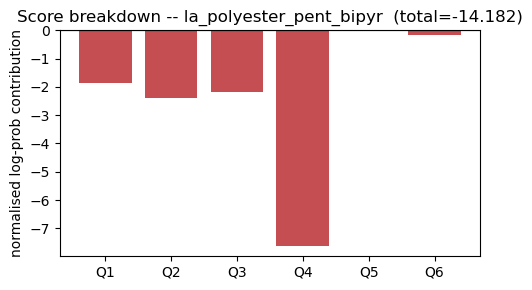

In [25]:
def score_breakdown_for(result, conformer=None) -> dict[str, float]:
    conformer = conformer or result.best
    X = torch.tensor(
        np.stack([a.position for a in conformer.complex.atoms]), dtype=torch.float32
    ).unsqueeze(0)
    _, breakdown = result.scorer.score(X)
    return {k: float(v.item()) for k, v in breakdown.items()}


def plot_score_breakdown(result, title=""):
    bd = score_breakdown_for(result)
    fig, ax = plt.subplots(figsize=(5, 3))
    keys = list(bd.keys())
    vals = [bd[k] for k in keys]
    colors = ["#4c72b0" if v >= 0 else "#c44e52" for v in vals]
    ax.bar(keys, vals, color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("normalised log-prob contribution")
    ax.set_title(f"Score breakdown -- {title}  (total={sum(vals):.3f})")
    plt.tight_layout()
    plt.show()
    return bd


# Example: EDTA, the flagship stress case
plot_score_breakdown(RESULTS["la_polyester_pent_bipyr"], "la_polyester_pent_bipyr");


## 6. IK convergence trace

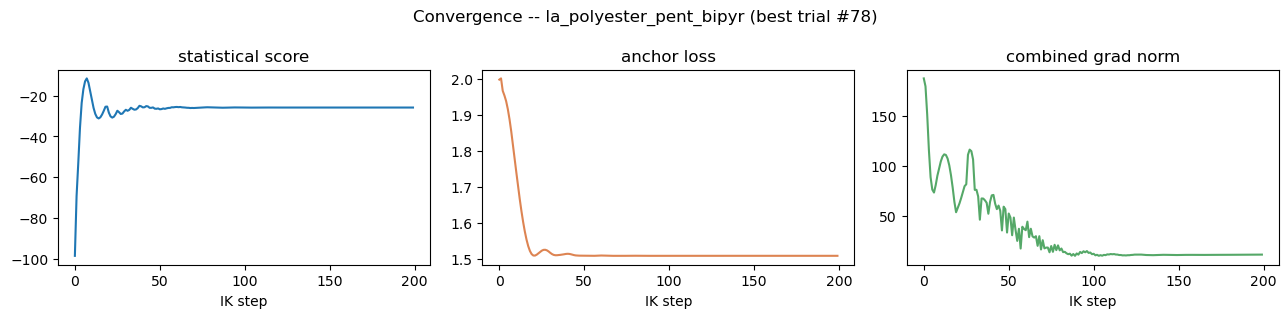

In [26]:
def plot_convergence(result, case_name=""):
    trace = result.solve_trace
    if not trace:
        print("No solve_trace on this result.")
        return
    b = result.best.trial_idx  # column into (T, B) trace arrays for the selected trial
    T = trace["score"].shape[0]
    steps = np.arange(T)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    axes[0].plot(steps, trace["score"][:, b])
    axes[0].set_title("statistical score"); axes[0].set_xlabel("IK step")
    axes[1].plot(steps, trace["anchor_loss"][:, b], color="#dd8452")
    axes[1].set_title("anchor loss"); axes[1].set_xlabel("IK step")
    axes[2].plot(steps, trace["grad_norm"][:, b], color="#55a868")
    axes[2].set_title("combined grad norm"); axes[2].set_xlabel("IK step")
    fig.suptitle(f"Convergence -- {case_name} (best trial #{b})")
    plt.tight_layout()
    plt.show()


plot_convergence(RESULTS["la_polyester_pent_bipyr"], "la_polyester_pent_bipyr")


## 7. D&ndash;M&ndash;D angle diagnostic

The most direct view onto the Q2 shape-enforcement question: is the donor
set actually sitting where the requested geometry says it should?


In [24]:
plot_dmd_angles(RESULTS["la_polyester_pent_bipyr"], CASES_BY_NAME["la_polyester_pent_bipyr"])

NameError: name 'plot_dmd_angles' is not defined

## 8. 3D structure

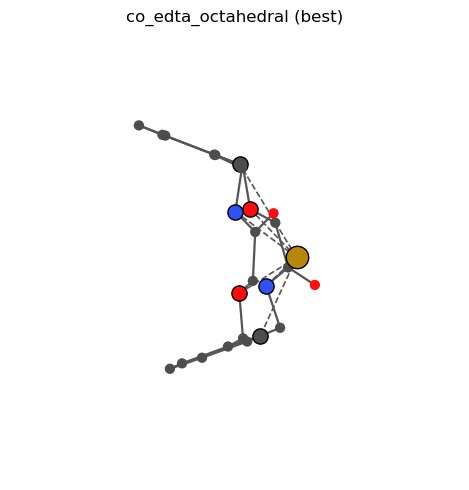

In [27]:
_ELEMENT_COLORS = {
    "H": "#dddddd", "C": "#4d4d4d", "N": "#3050f8", "O": "#ff0d0d",
    "P": "#ff8000", "S": "#ffff30", "Cl": "#1ff01f", "F": "#90e050",
}
_METAL_COLOR = "#b8860b"


def plot_structure_3d(mol, title="", show_hydrogen=False, elev=20, azim=35):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(111, projection="3d")

    donor_set = set(mol.donor_labels.keys())
    for a in mol.atoms:
        if a.symbol == "H" and not show_hydrogen:
            continue
        color = _METAL_COLOR if a.idx == mol.metal_idx else _ELEMENT_COLORS.get(a.symbol, "#999999")
        size = 260 if a.idx == mol.metal_idx else (120 if a.idx in donor_set else 55)
        edge = "black" if a.idx in donor_set or a.idx == mol.metal_idx else "none"
        ax.scatter(*a.position, color=color, s=size, edgecolors=edge, linewidths=1.0, depthshade=True)

    atom_map = {a.idx: a for a in mol.atoms}
    for b in mol.bonds:
        ai, aj = atom_map.get(b.i), atom_map.get(b.j)
        if ai is None or aj is None:
            continue
        if not show_hydrogen and (ai.symbol == "H" or aj.symbol == "H"):
            continue
        style = "--" if (b.i == mol.metal_idx or b.j == mol.metal_idx) else "-"
        lw = 1.2 if style == "--" else 1.6
        ax.plot(*zip(ai.position, aj.position), style, color="#555555", linewidth=lw)

    ax.set_title(title)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


plot_structure_3d(RESULTS["la_polyester_pent_bipyr"].best.complex, "co_edta_octahedral (best)")


In [28]:
from jacobik import Visualizer
vis = Visualizer(RESULTS["la_polyester_pent_bipyr"], show_hydrogen=False)
vis.view_ensemble_structs()

If `jacobik.vis.Visualizer` and its `ipywidgets`/`matplotlib` stack are
available in your kernel, it gives a richer interactive view (ensemble
overlay, ranking, heatmap) &mdash; try it for any case:

```python
from jacobik import Visualizer
vis = Visualizer(RESULTS["la_polyester_pent_bipyr"], show_hydrogen=False)
vis.view_ensemble_structs()
```

The `plot_structure_3d` above is the dependency-free fallback used
throughout this notebook so the dashboard always renders regardless of
what's installed in a given kernel.


## 9. Ensemble diversity

In [ ]:
def plot_rmsd_heatmap(result, case_name=""):
    M = pairwise_rmsd_matrix(result.conformers)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(f"Pairwise heavy-atom RMSD -- {case_name}\n(near-zero off-diagonal = collapsed ensemble)")
    ax.set_xlabel("conformer rank"); ax.set_ylabel("conformer rank")
    fig.colorbar(im, ax=ax, label="RMSD (A)")
    plt.tight_layout()
    plt.show()
    return M


_ = plot_rmsd_heatmap(RESULTS["la_polyester_pent_bipyr"], "la_polyester_pent_bipyr")


## 10. Stats introspection &mdash; which fallback level fired?

`StatsLookup.dist_trace(quantity, key)` shows exactly which candidate key a
lookup resolved to. Use this whenever a case's geometry looks
statistically underdetermined, or to directly confirm the spin/multiplicity
fix: a diamagnetic Co(III) Q1 query should now resolve at **level 0** (the
exact key), not fall through to a coarse geometry-blind fallback.


In [ ]:
print("--- la_polyester_pent_bipyr ---")
mol = RESULTS["la_polyester_pent_bipyr"].best.complex
some_donor = next(iter(mol.donor_labels))
inspect_q1_for_donor(mol, some_donor, "pent_bipyr")

## 13. Debugging playground

Pick any registered case, rerun with `debug=True` for full solver
diagnostics (printed inline by the engine), and get every plot above in one
place. Edit `CASE_NAME` and any `overrides` and rerun this cell.


In [ ]:
CASE_NAME = "la_polyester_pent_bipyr"
case = CASES_BY_NAME[CASE_NAME]

result, elapsed = run_case(case, debug=True)  # add overrides as kwargs, e.g. seed=7, beam_width=32
checks = run_all_checks(result, case)

print("\n=== checks ===")
for k, v in checks.items():
    print(f"  {k:14s} pass={v['pass']!s:5}  {v.get('message', '')}")

plot_score_breakdown(result, CASE_NAME)
plot_convergence(result, CASE_NAME)
plot_dmd_angles(result, case)
plot_structure_3d(result.best.complex, f"{CASE_NAME} (best)")
_ = plot_rmsd_heatmap(result, CASE_NAME)
